In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from scipy.stats import binomtest

In [2]:
df = pd.read_csv("heart.csv")

print(df.head())
print("Dataset Shape:", df.shape)
print(df.info())

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
Dataset Shape: (918, 12)
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  ----- 

In [3]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (918, 11)
Target: (918,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (734, 11)
Testing: (184, 11)


In [5]:
num_cols = X_train.select_dtypes(include=np.number).columns
cat_cols = X_train.select_dtypes(exclude=np.number).columns

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed")

Preprocessing Completed


In [6]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

In [7]:
def manual_metrics(y_true, y_pred):

    cm = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        cm[int(actual), int(predicted)] += 1

    tn, fp = cm[0, 0], cm[0, 1]
    fn, tp = cm[1, 0], cm[1, 1]

    accuracy = (tp + tn) / (tp + tn + fp + fn)

    precision = tp / (tp + fp) if (tp + fp) else 0

    recall = tp / (tp + fn) if (tp + fn) else 0

    specificity = tn / (tn + fp) if (tn + fp) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1 Score": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

In [8]:
results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train_processed, y_train)

    train_pred = model.predict(X_train_processed)
    test_pred = model.predict(X_test_processed)

    train_metrics = manual_metrics(y_train, train_pred)
    test_metrics = manual_metrics(y_test, test_pred)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Train Accuracy": train_metrics["Accuracy"],
        "Test Accuracy": test_metrics["Accuracy"],
        "Precision": test_metrics["Precision"],
        "Recall": test_metrics["Recall"],
        "Specificity": test_metrics["Specificity"],
        "F1 Score": test_metrics["F1 Score"],
        "False Positives": test_metrics["FP"],
        "False Negatives": test_metrics["FN"]
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Train Accuracy  Test Accuracy  Precision  Recall  \
0  Logistic Regression          0.8542         0.8967     0.8879  0.9314   
1        Decision Tree          1.0000         0.7826     0.8039  0.8039   
2        Random Forest          1.0000         0.9022     0.8962  0.9314   
3                  SVM          0.8992         0.8913     0.8942  0.9118   
4                  KNN          0.8815         0.8967     0.9109  0.9020   

   Specificity  F1 Score  False Positives  False Negatives  
0       0.8537    0.9091               12                7  
1       0.7561    0.8039               20               20  
2       0.8659    0.9135               11                7  
3       0.8659    0.9029               11                9  
4       0.8902    0.9064                9               10  


In [9]:
results_df["Train_Test_Gap"] = abs(
    results_df["Train Accuracy"] -
    results_df["Test Accuracy"]
)

results_df["Overfitting Status"] = np.where(
    results_df["Train_Test_Gap"] < 0.05,
    "Low Gap",
    np.where(
        results_df["Train_Test_Gap"] < 0.10,
        "Moderate Gap",
        "High Gap"
    )
)

print(
    results_df[
        ["Model", "Train Accuracy", "Test Accuracy",
         "Train_Test_Gap", "Overfitting Status"]
    ].round(4)
)

                 Model  Train Accuracy  Test Accuracy  Train_Test_Gap  \
0  Logistic Regression          0.8542         0.8967          0.0425   
1        Decision Tree          1.0000         0.7826          0.2174   
2        Random Forest          1.0000         0.9022          0.0978   
3                  SVM          0.8992         0.8913          0.0079   
4                  KNN          0.8815         0.8967          0.0153   

  Overfitting Status  
0            Low Gap  
1           High Gap  
2       Moderate Gap  
3            Low Gap  
4            Low Gap  


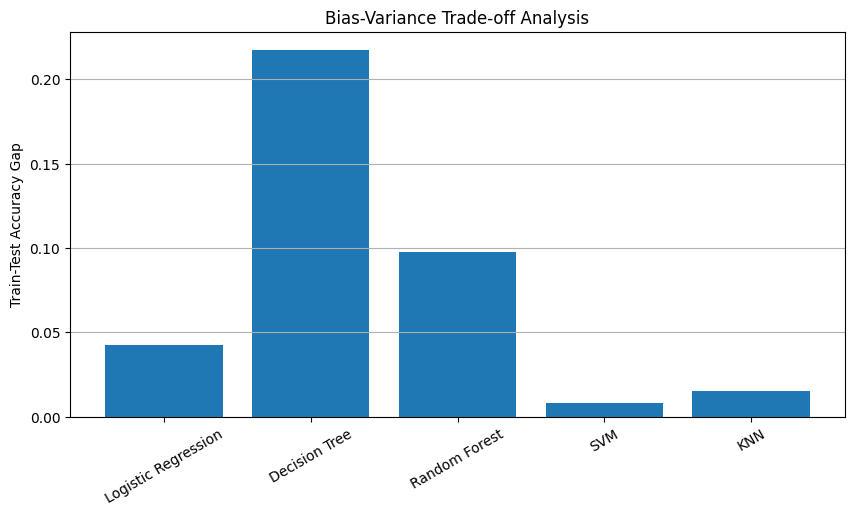

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Train_Test_Gap"]
)

plt.title("Bias-Variance Trade-off Analysis")
plt.ylabel("Train-Test Accuracy Gap")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

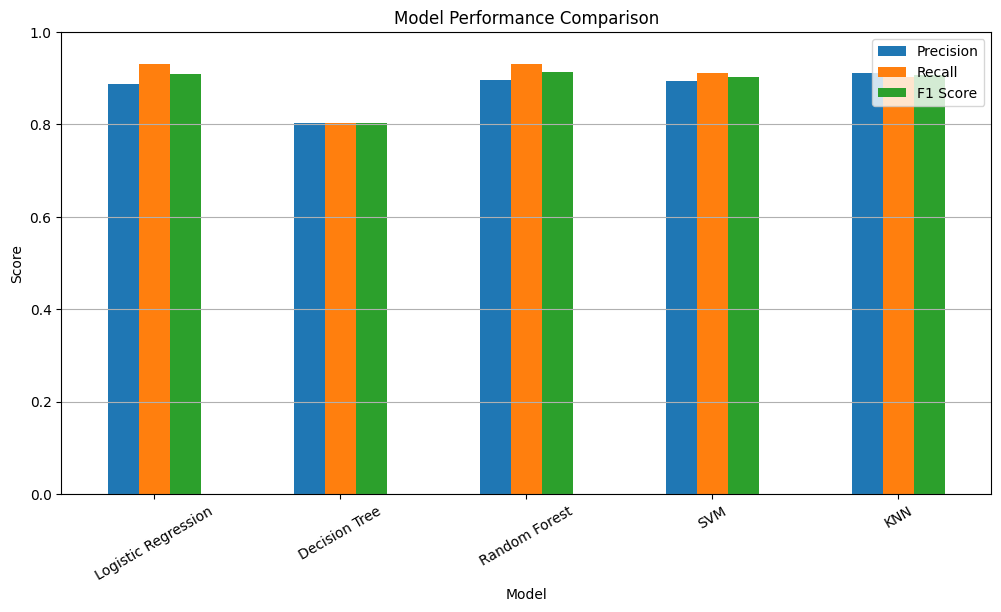

In [11]:
results_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

In [12]:
from sklearn.metrics import f1_score

ranked = results_df.sort_values(
    "F1 Score",
    ascending=False
).reset_index(drop=True)

model_1_name = ranked.loc[0, "Model"]
model_2_name = ranked.loc[1, "Model"]

pred_1 = trained_models[model_1_name].predict(X_test_processed)
pred_2 = trained_models[model_2_name].predict(X_test_processed)

actual = np.asarray(y_test)

rng = np.random.default_rng(42)
differences = []

for i in range(2000):

    indices = rng.integers(0, len(actual), len(actual))

    score_1 = f1_score(
        actual[indices],
        pred_1[indices],
        zero_division=0
    )

    score_2 = f1_score(
        actual[indices],
        pred_2[indices],
        zero_division=0
    )

    differences.append(score_1 - score_2)

differences = np.array(differences)

lower = np.percentile(differences, 2.5)
upper = np.percentile(differences, 97.5)

print("Model 1:", model_1_name)
print("Model 2:", model_2_name)

print("Mean F1 Difference:", differences.mean())
print("95% Confidence Interval:", lower, upper)

if lower > 0 or upper < 0:
    print("Statistically distinguishable F1 difference")
else:
    print("No clear statistical difference established")

Model 1: Random Forest
Model 2: Logistic Regression
Mean F1 Difference: 0.004755966574663359
95% Confidence Interval: -0.02520868569488739 0.03389019731932767
No clear statistical difference established


In [13]:
correct_1 = (pred_1 == actual)
correct_2 = (pred_2 == actual)

b = np.sum(correct_1 & ~correct_2)
c = np.sum(~correct_1 & correct_2)

n = b + c

if n > 0:

    result = binomtest(
        min(b, c),
        n=n,
        p=0.5,
        alternative="two-sided"
    )

    print("Model 1 only correct:", b)
    print("Model 2 only correct:", c)
    print("P-value:", result.pvalue)

    if result.pvalue < 0.05:
        print("Significant difference found")
    else:
        print("No significant difference found")

else:
    print("Both models made identical predictions")

Model 1 only correct: 6
Model 2 only correct: 5
P-value: 1.0
No significant difference found


In [14]:
results_df["Custom Score"] = (
    0.30 * results_df["Precision"] +
    0.40 * results_df["Recall"] +
    0.30 * results_df["F1 Score"]
)

final_results = results_df.sort_values(
    "Custom Score",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL RANKING")
print(final_results.round(4))

best_model_name = final_results.loc[0, "Model"]

print("\nBest Model:", best_model_name)

FINAL MODEL RANKING
                 Model  Train Accuracy  Test Accuracy  Precision  Recall  \
0        Random Forest          1.0000         0.9022     0.8962  0.9314   
1  Logistic Regression          0.8542         0.8967     0.8879  0.9314   
2                  KNN          0.8815         0.8967     0.9109  0.9020   
3                  SVM          0.8992         0.8913     0.8942  0.9118   
4        Decision Tree          1.0000         0.7826     0.8039  0.8039   

   Specificity  F1 Score  False Positives  False Negatives  Train_Test_Gap  \
0       0.8659    0.9135               11                7          0.0978   
1       0.8537    0.9091               12                7          0.0425   
2       0.8902    0.9064                9               10          0.0153   
3       0.8659    0.9029               11                9          0.0079   
4       0.7561    0.8039               20               20          0.2174   

  Overfitting Status  Custom Score  
0       Moderate 

# Conclusion:

# Multiple machine learning models were implemented and compared for Heart Disease Prediction. Evaluation metrics such as Accuracy, Precision, Recall, F1-score, and Specificity were manually calculated using the confusion matrix.

# The bias-variance trade-off was analyzed by comparing training and testing performance. Statistical significance was investigated using paired bootstrap confidence intervals and McNemar's test.

# A custom weighted scoring strategy was used, assigning 30% weight to Precision, 40% to Recall, and 30% to F1-score. The model with the highest weighted score was selected as the preferred model.

# The final selection considered predictive performance, generalization ability, and statistical evidence rather than accuracy alone